# Avaliação final: como a configuração congelada se comporta em instâncias nunca usadas?

Este notebook examina resultados congelados em `outputs/frozen/evaluation/` para avaliar o desempenho da configuração selecionada do OR-Tools (Perron & Furnon, 2026) nas 42 instâncias de avaliação mantidas fora do torneio e do ajuste de orçamento, sem executar nenhum solver durante a leitura.

Conforme o protocolo pré-registrado em `reports/protocolo-avaliacao.md` (Nosek et al., 2018), a configuração congelada `fixed_cost` + `SAVINGS` (Clarke & Wright, 1964) + `GUIDED_LOCAL_SEARCH` (Voudouris & Tsang, 1999) rodou sem modificações por 120 s em 5 réplicas por instância (210 execuções do OR-Tools, somadas a 84 execuções únicas das duas baselines determinísticas, totalizando 294 células; Barr et al., 1995). O orçamento subiu dos 30 s do torneio para 120 s com base na curva de tempo das instâncias de desenvolvimento (notebook 04, seção 7), na qual o Δ médio recuou de 1,00 (10 s) até 0,64 (120 s) antes de estabilizar em 300 s.

Adotou-se como resultado principal a réplica mediana (3ª de 5 após ordenação lexicográfica por factibilidade, veículos e distância), reportando a melhor réplica apenas em tabela paralela. Frente ao SINTEF, Δ de veículos e gap de distância permanecem separados e o gap aplica-se somente sob frota igual, sem testes de significância nem alegação de otimalidade, mantendo as decisões intactas após a abertura dos resultados (Kaufman et al., 2012). A seção 11 acrescenta, lado a lado e sem substituir a v1, a reavaliação pós-hoc da configuração v2 (`reports/protocolo-fase-d.md`).

## 1. Preparação do ambiente

Nesta etapa carregam-se o split, a configuração efetiva (`config/experiment.toml`), a configuração congelada e os resultados da avaliação, derivando a tabela por instância (réplica mediana, melhor de 5 e amplitude). A tabela resume os parâmetros efetivos.

In [1]:
LANG = "pt"  # "pt" or "en"

import matplotlib.pyplot as plt
from IPython.display import display

from delivery_routing_vrptw import (
    benchmark,
    config,
    eda,
    evaluation,
    final_eval,
    paths,
    results,
    viz_final,
    viz_results,
)
from delivery_routing_vrptw.viz import setup_notebook_figures

setup_notebook_figures()

P = paths.data_paths()
R = paths.result_paths()
split = benchmark.read_split(P["split"])
cfg = config.load_config()
selected = results.load_selected_config(R["selected_config"], split)
rows = results.load_evaluation(R["evaluation"], split)
inst = evaluation.instance_table(rows)

display(eda.localize_columns(final_eval.protocol_table(cfg, selected, LANG), LANG))

,Indicador,Valor
0,Estratégia de frota (congelada),fixed_cost
1,Solução inicial (congelada),SAVINGS
2,Metaheurística (congelada),GUIDED_LOCAL_SEARCH
3,Orçamento do torneio (s),30
4,Orçamento da avaliação (s por execução),120
5,Réplicas por instância,5
6,Resultado principal,réplica mediana (posição 3 de 5)
7,Baselines (1 execução por instância),sim
8,Conjunto de instâncias,eval


### Insight

Os parâmetros carregados coincidem integralmente com o protocolo pré-registrado: `fixed_cost` + `SAVINGS` + `GUIDED_LOCAL_SEARCH`, 120 s por execução, 5 réplicas com resultado principal na mediana (3ª posição), baselines presentes e conjunto `eval`. Como o arquivo de configuração é lido no momento da execução do notebook, a correspondência exata com o que rodou no experimento é garantida pelo protocolo e pelos metadados congelados. Em seguida confere-se a integridade dos resultados salvos.

## 2. Integridade da execução

Para validar a completude e o isolamento do conjunto de avaliação, a tabela conta o total de células, os subconjuntos por método, as instâncias distintas, eventuais casos de desenvolvimento, a factibilidade em precisão dupla, os status do solver e os tempos de relógio.

In [2]:
display(eda.localize_columns(final_eval.integrity_table(rows, split, LANG), LANG))

,Indicador,Valor
0,Células no arquivo (total),294
1,Células do OR-Tools (instâncias × réplicas),210
2,Células das baselines,84
3,Instâncias distintas,42
4,Instâncias de avaliação no split,42
5,Instâncias de desenvolvimento nos resultados,0
6,Réplicas do OR-Tools por instância,5
7,Células factíveis no verificador,294 / 294
8,Execuções do OR-Tools com status de sucesso,210 / 210
9,Tempo médio por execução do OR-Tools (s),120.0


### Insight

O arquivo congelado reúne 294 células, 210 do OR-Tools (42 instâncias em 5 réplicas) e 84 das baselines (2 vezes 42), cobrindo exatamente as 42 instâncias de avaliação sem contaminação do conjunto de desenvolvimento. Todas as 294 soluções passam no verificador em precisão dupla e as 210 execuções do OR-Tools terminaram com sucesso, consumindo o orçamento integral de 120,0 s (variação de 120,00 a 120,04 s). Atingida a validação estrutural, a seção 3 mede a qualidade contra a referência do SINTEF.

## 3. Resultado principal contra o SINTEF

As tabelas comparam o desempenho frente ao SINTEF (SINTEF, 2008) no geral e por família, listando contagem de instâncias, Δ médio de veículos, igualdades de frota, gap mediano de distância sob frota igual e número de instâncias que superam a referência na ordem hierárquica (Bräysy & Gendreau, 2005a). A primeira tabela traz o resultado principal (réplica mediana) e a segunda, em caráter auxiliar, a melhor das 5 réplicas.

In [3]:
display(eda.localize_columns(final_eval.main_table(rows, LANG), LANG))
display(eda.localize_columns(final_eval.main_table(rows, LANG, best=True), LANG))

,Resultado,Escopo,Nº de instâncias,Δ veículos médio,Instâncias com frota igual à referência,"Gap mediano, frota igual (%)",Supera a referência
0,Réplica mediana (resultado principal),Geral,42,0.50,24,3.4,0
1,Réplica mediana (resultado principal),C1,7,0.00,7,0.0,0
2,Réplica mediana (resultado principal),C2,6,0.00,6,0.0,0
3,Réplica mediana (resultado principal),R1,9,0.89,1,0.52,0
4,Réplica mediana (resultado principal),R2,8,0.25,6,5.02,0
5,Réplica mediana (resultado principal),RC1,6,1.50,0,-,0
6,Réplica mediana (resultado principal),RC2,6,0.33,4,4.63,0


,Resultado,Escopo,Nº de instâncias,Δ veículos médio,Instâncias com frota igual à referência,"Gap mediano, frota igual (%)",Supera a referência
0,Melhor de 5 (à parte),Geral,42,0.50,24,2.65,0
1,Melhor de 5 (à parte),C1,7,0.00,7,0.0,0
2,Melhor de 5 (à parte),C2,6,0.00,6,0.0,0
3,Melhor de 5 (à parte),R1,9,0.89,1,0.52,0
4,Melhor de 5 (à parte),R2,8,0.25,6,4.01,0
5,Melhor de 5 (à parte),RC1,6,1.50,0,-,0
6,Melhor de 5 (à parte),RC2,6,0.33,4,4.63,0


### Insight

Na réplica mediana, o OR-Tools registra Δ médio de 0,50 veículo sobre as 42 instâncias, igualando a frota do SINTEF em 24 casos e sem superar nenhuma referência, com gap mediano de distância de 3,40% entre as 24 igualdades. Por família, C1 e C2 atingem Δ 0,00 com igualdade de frota em todas as instâncias (7/7 e 6/6) e gap mediano de 0,00%; R1 obtém Δ 0,89 e 1 igualdade em 9 (gap 0,52%); R2 marca Δ 0,25 e 6 igualdades em 8 (gap mediano 5,02%); RC1 registra Δ 1,50 sem igualdades (0/6); e RC2 obtém Δ 0,33 com 4 igualdades em 6 (gap mediano 4,63%).

Tomar a melhor das 5 réplicas preserva o Δ médio de 0,50 e as 24 igualdades de frota em todos os grupos, reduzindo apenas os gaps medianos (de 3,40% para 2,65% no geral e de 5,02% para 4,01% em R2). Como os valores SINTEF são soluções heurísticas conhecidas e os subconjuntos de frota igual variam de tamanho entre famílias (tendo R1 um único caso), esses percentuais permanecem descritivos. A distribuição detalhada de Δ de veículos é examinada na seção 4.

## 4. Distribuição do Δ de veículos

Para verificar se o Δ médio reflete poucos extremos ou pequenos desvios frequentes, a tabela e o gráfico de barras empilhadas contam as instâncias por valor inteiro de Δ na réplica mediana, destacando os casos com Δ igual ou superior a +2.

,Escopo,Nº de instâncias,Δ < 0,Δ = 0,Δ = +1,Δ = +2,Δ ≥ +3
0,Geral,42,0,24,15,3,0
1,C1,7,0,7,0,0,0
2,C2,6,0,6,0,0,0
3,R1,9,0,1,8,0,0
4,R2,8,0,6,2,0,0
5,RC1,6,0,0,3,3,0
6,RC2,6,0,4,2,0,0


,Instância,Família,Veículos SINTEF,Veículos,Δ veículos (vs SINTEF)
0,RC101,RC1,14,16,2
1,RC102,RC1,12,14,2
2,RC105,RC1,13,15,2


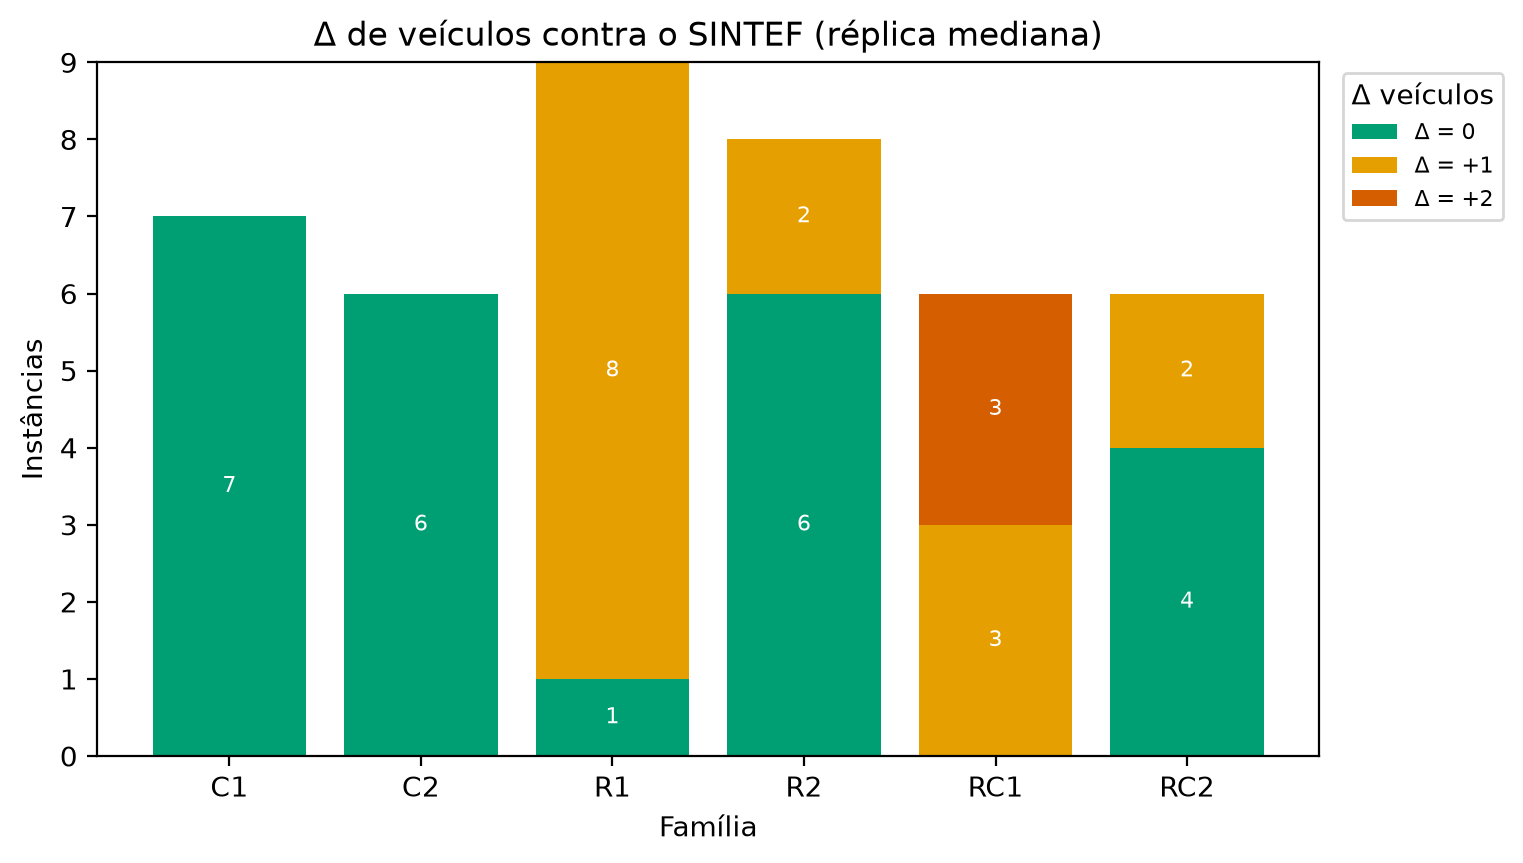

In [4]:
display(eda.localize_columns(final_eval.delta_distribution(inst, LANG), LANG))
display(eda.localize_columns(final_eval.delta_instances(inst, 2), LANG))

viz_final.plot_delta_distribution(inst, LANG)
plt.show()

### Insight

Das 42 instâncias, 24 apresentam Δ igual a 0, 15 têm +1 veículo e 3 têm +2 (RC101, RC102 e RC105), sem nenhum caso abaixo da referência nem acima de +2. Todas as 13 instâncias C empatam em Δ 0; em R1 há 1 caso com 0 e 8 com +1; em R2 há 6 com 0 e 2 com +1; em RC1 dividem-se igualmente entre 3 casos com +1 e 3 com +2; e em RC2 há 4 com 0 e 2 com +1. Assim, o Δ médio de 0,50 decorre de desvios moderados concentrados em R1 e RC1, cabendo observar que 1 veículo extra tem peso relativo distinto em frotas de 2 ou de 19 veículos. A seção 5 analisa o comportamento da distância onde as frotas empatam.

## 5. Instâncias com frota igual à da referência

Esta seção sintetiza as 24 instâncias com igualdade de frota, listando quantas reproduzem a distância de referência ao centésimo (diferença de no máximo 0,005), quantas ficam acima, os gaps medianos e máximos e um gráfico colorido por família.

,Escopo,Nº de instâncias,Instâncias com frota igual à referência,Reproduzem a distância ao centésimo,"Frota igual, distância acima","Gap mediano, frota igual (%)",Gap máximo (%)
0,Geral,42,24,10,14,3.4,7.92
1,C1,7,7,5,2,0.0,7.92
2,C2,6,6,5,1,0.0,3.6
3,R1,9,1,0,1,0.52,0.52
4,R2,8,6,0,6,5.02,7.83
5,RC1,6,0,0,0,-,-
6,RC2,6,4,0,4,4.63,5.67


,Instância,Família,Veículos SINTEF,Distância SINTEF,Veículos,Distância,Gap de distância (%),Reproduz a distância (ao centésimo)
0,C101,C1,10,828.94,10,828.94,0.00,Sim
1,C102,C1,10,828.94,10,828.94,0.00,Sim
2,C104,C1,10,824.78,10,888.28,7.70,Não
3,C105,C1,10,828.94,10,828.94,0.00,Sim
4,C107,C1,10,828.94,10,828.94,0.00,Sim
5,C108,C1,10,828.94,10,828.94,0.00,Sim
6,C109,C1,10,828.94,10,894.60,7.92,Não
7,C201,C2,3,591.56,3,591.56,0.00,Sim
8,C202,C2,3,591.56,3,591.56,0.00,Sim
9,C204,C2,3,590.60,3,611.88,3.60,Não


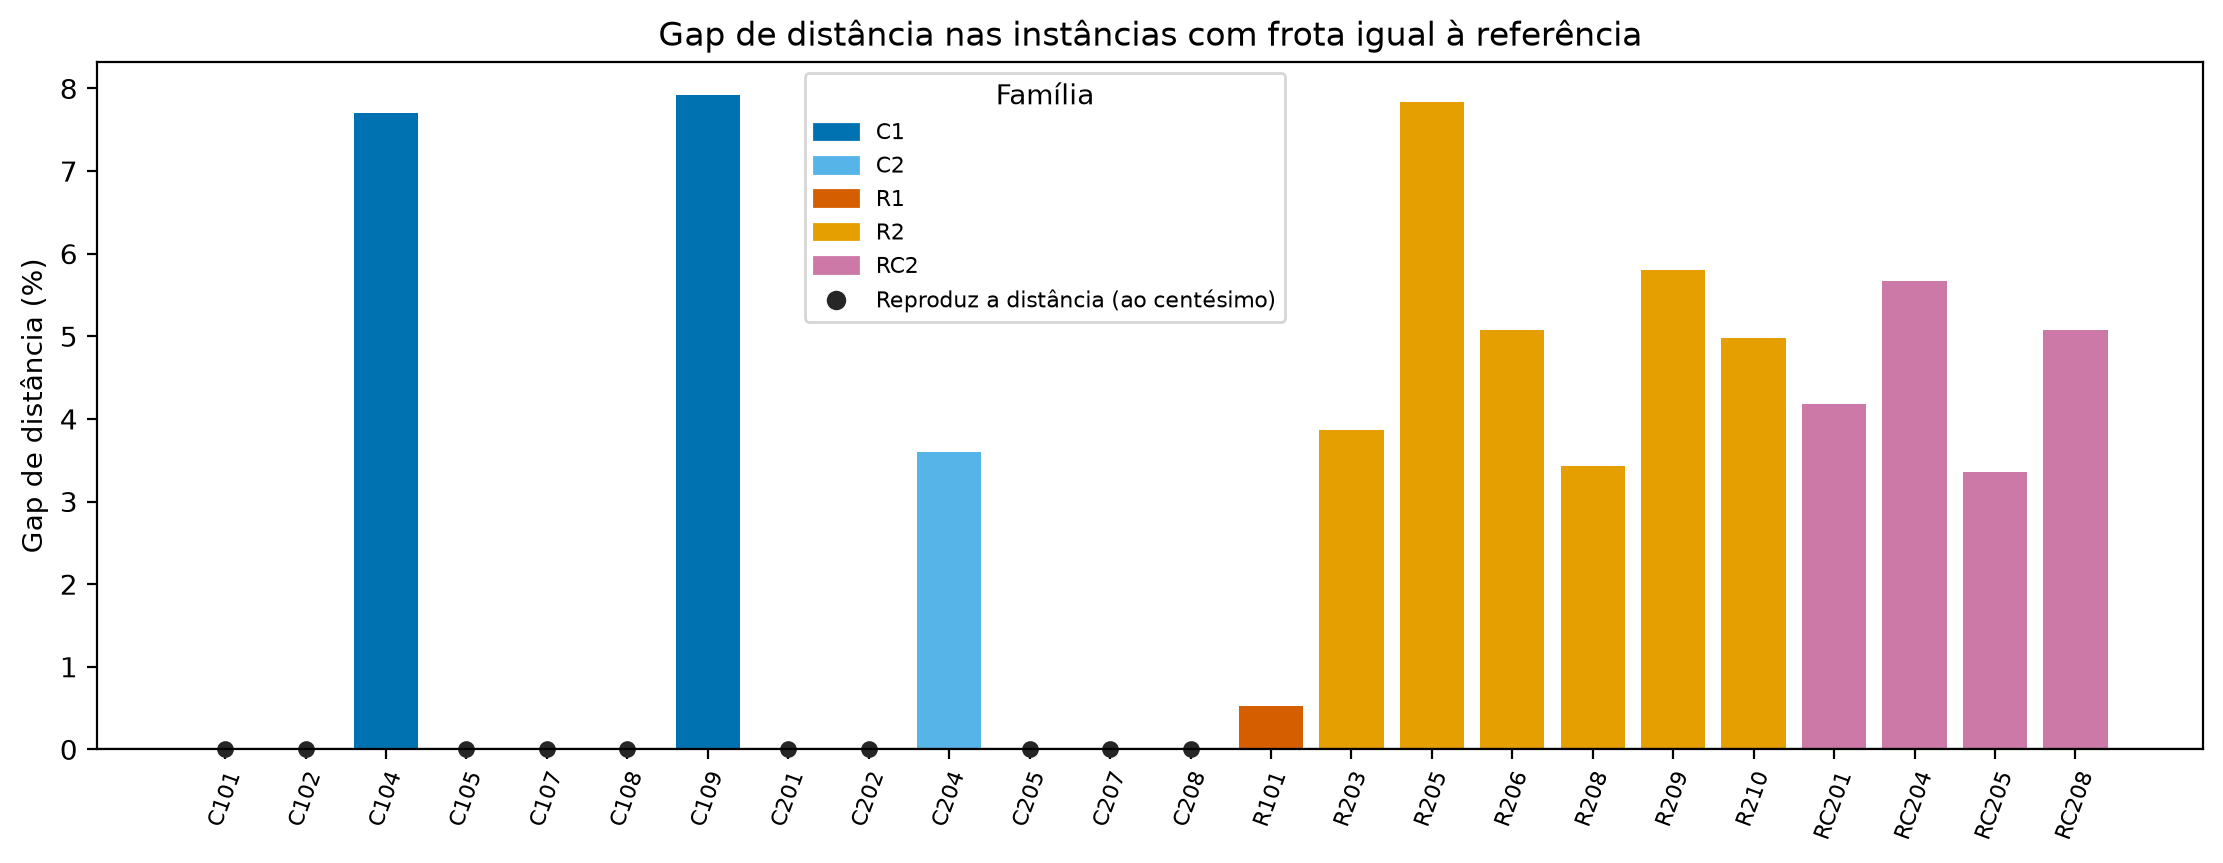

In [5]:
display(eda.localize_columns(final_eval.reproduction_summary(inst, LANG), LANG))
display(eda.localize_columns(final_eval.fleet_equal_table(inst, LANG), LANG))

viz_final.plot_gap_fleet_equal(inst, LANG)
plt.show()

### Insight

Entre as 24 instâncias com frota igual, 10 reproduzem a distância do SINTEF ao centésimo, todas pertencentes às famílias C (5 de 7 em C1 e 5 de 6 em C2), enquanto as outras 3 da classe C ficam acima (C104 em 7,70%, C109 em 7,92% e C204 em 3,60%). Nenhuma instância R ou RC iguala a distância de referência: R101 tem gap de 0,52% e as 10 instâncias de séries 2 (6 de R2 e 4 de RC2) apresentam gaps entre 3,36% (RC205) e 7,83% (R205), resultando em mediana geral de 3,40% e máximo de 7,92%. Nas outras 18 instâncias com frota superior, eventual distância menor não representa ganho na ordem lexicográfica. Na seção 6 mede-se a dispersão entre as 5 réplicas.

## 6. Variabilidade entre as 5 réplicas

A tabela quantifica, por escopo, quantas instâncias variaram em número de veículos ou em distância entre as 5 réplicas (amplitude em percentual do mínimo entre planos factíveis), listando os casos individuais com diferença de distância.

In [6]:
display(eda.localize_columns(final_eval.variability_table(inst, LANG), LANG))
display(eda.localize_columns(final_eval.varying_instances(inst), LANG))

,Escopo,Nº de instâncias,Instâncias com frota variável,Maior amplitude de frota,Instâncias com distância variável,Amplitude mediana da distância (%),Amplitude máxima da distância (%)
0,Geral,42,0,0,6,0.00,3.21
1,C1,7,0,0,0,0.00,0.00
2,C2,6,0,0,0,0.00,0.00
3,R1,9,0,0,0,0.00,0.00
4,R2,8,0,0,4,0.37,3.21
5,RC1,6,0,0,0,0.00,0.00
6,RC2,6,0,0,2,0.00,0.79


,Instância,Família,Veículos,Distância mínima,Distância,Distância máxima,Amplitude (%)
0,R203,R2,3,974.38,975.82,1005.65,3.21
1,R209,R2,3,934.08,961.85,961.85,2.97
2,R211,R2,3,826.83,837.54,837.54,1.30
3,RC205,RC2,4,1330.76,1341.31,1341.31,0.79
4,R206,R2,3,945.12,952.09,952.09,0.74
5,RC204,RC2,3,841.21,843.71,843.71,0.30


### Insight

O tamanho da frota foi idêntico nas 5 réplicas em todas as 42 instâncias (amplitude zero). A distância variou em apenas 6 casos de séries 2: R203 (3,21%), R209 (2,97%), R211 (1,30%), R206 (0,74%), RC205 (0,79%) e RC204 (0,30%), mantendo mediana geral de amplitude em 0,00% e variabilidade nula em C1, C2, R1 e RC1. Embora nas instâncias de desenvolvimento a 30 s tenham ocorrido variações de ±1 veículo (`reports/sensibilidade-tempo-e-janelas.md`), nesta avaliação a 120 s em máquina sem outra carga a frota estabilizou-se nas 29 instâncias R e RC, ainda que mudanças simultâneas de orçamento, amostra e carga impeçam isolar a causa dessa estabilidade. Em seguida, o OR-Tools é contrastado com as baselines.

## 7. Baselines contra o OR-Tools

As tabelas comparam a réplica mediana do OR-Tools frente às execuções determinísticas da gulosa por prazo e do vizinho mais próximo com janelas, no agregado e por família.

In [7]:
display(eda.localize_columns(final_eval.method_comparison(rows, LANG), LANG))
display(eda.localize_columns(final_eval.method_by_family(rows, LANG), LANG))

,Método,Nº de instâncias,Factíveis,Δ veículos médio,Instâncias com frota igual à referência,"Gap mediano, frota igual (%)",Supera a referência
0,OR-Tools,42,42,0.50,24,3.4,0
1,Vizinho mais próximo com janelas,42,42,1.36,12,71.59,0
2,Gulosa por prazo,42,42,3.98,2,94.83,0


,Método,Geral,C1,C2,R1,R2,RC1,RC2
0,OR-Tools,0.50,0.00,0.00,0.89,0.25,1.50,0.33
1,Vizinho mais próximo com janelas,1.36,0.29,0.33,2.78,0.88,2.83,0.67
2,Gulosa por prazo,3.98,1.43,1.50,6.56,3.00,7.33,3.50


### Insight

O OR-Tools lidera em todas as seis famílias com Δ médio de 0,50 veículo e 24 igualdades de frota, contra 1,36 e 12 igualdades do vizinho mais próximo e 3,98 e 2 igualdades da gulosa por prazo. A diferença acentua-se nas séries críticas: em R1 os deltas médios são 0,89 contra 2,78 e 6,56, e em RC1 são 1,50 contra 2,83 e 7,33; já nas famílias C o vizinho mais próximo se aproxima (0,29 em C1 e 0,33 em C2 contra 0,00 do OR-Tools). O gap mediano de distância sob frota igual fica em 3,40% no OR-Tools contra 71,59% no vizinho mais próximo e 94,83% na gulosa, calculados sobre conjuntos diferentes (24, 12 e 2 instâncias) e demonstrando apenas ganho substancial sobre heurísticas construtivas simples. A seção 8 confronta a avaliação com o conjunto de desenvolvimento.

## 8. Consistência com o desenvolvimento

Para conferir de forma puramente descritiva a coerência entre as duas partições sob o mesmo orçamento de 120 s, comparam-se as execuções únicas do estudo de tempo no desenvolvimento (14 instâncias, notebook 04) com a réplica mediana da avaliação (42 instâncias), no total e por família.

In [8]:
time_df = results.load_time_sensitivity(R["time_sensitivity"], split)
budget = cfg.evaluation.time_limit_s

display(eda.localize_columns(final_eval.dev_vs_eval(time_df, inst, budget, LANG), LANG))
display(eda.localize_columns(final_eval.dev_vs_eval_by_family(time_df, inst, budget, LANG), LANG))

,Conjunto,Nº de instâncias,Execuções por instância,Δ veículos médio,Frota igual à referência,"Gap mediano, frota igual (%)"
0,Desenvolvimento,14,1,0.64,7 / 14,1.74
1,Avaliação,42,5,0.50,24 / 42,3.4


,Família,Desenvolvimento · Nº de instâncias,Desenvolvimento · Δ veículos médio,Desenvolvimento · Instâncias com frota igual à referência,Avaliação · Nº de instâncias,Avaliação · Δ veículos médio,Avaliação · Instâncias com frota igual à referência
0,C1,2,0.00,2,7,0.00,7
1,C2,2,0.00,2,6,0.00,6
2,R1,3,1.33,0,9,0.89,1
3,R2,3,0.67,1,8,0.25,6
4,RC1,2,1.50,0,6,1.50,0
5,RC2,2,0.00,2,6,0.33,4


### Insight

A 120 s, o conjunto de desenvolvimento (14 instâncias) obteve Δ médio de 0,64 e frota igual em 7 de 14 (gap mediano 1,74%), enquanto a avaliação (42 instâncias) registrou 0,50 e 24 de 42 (gap mediano 3,40%). O perfil familiar repete-se em linhas gerais: Δ 0,00 com 100% de igualdades nas famílias C; 1,50 sem igualdades em RC1; 1,33 contra 0,89 em R1; 0,67 contra 0,25 em R2; e 0,00 contra 0,33 em RC2. Os resultados mostram consistência geral de frota entre partições disjuntas, sem comparações diretas de gap devido à diferença dos subconjuntos (7 contra 24 casos) e ao tamanho reduzido de 2 ou 3 instâncias por família no desenvolvimento. A seção 9 visualiza as rotas de dois casos representativos.

## 9. Rotas da réplica mediana

Os mapas exibem as rotas da réplica mediana para C101 (primeira instância C que reproduz a distância SINTEF ao centésimo) e RC101 (primeira instância RC1 com o maior Δ da família), destacando o depósito em vermelho e o resumo de veículos e distância nos títulos.

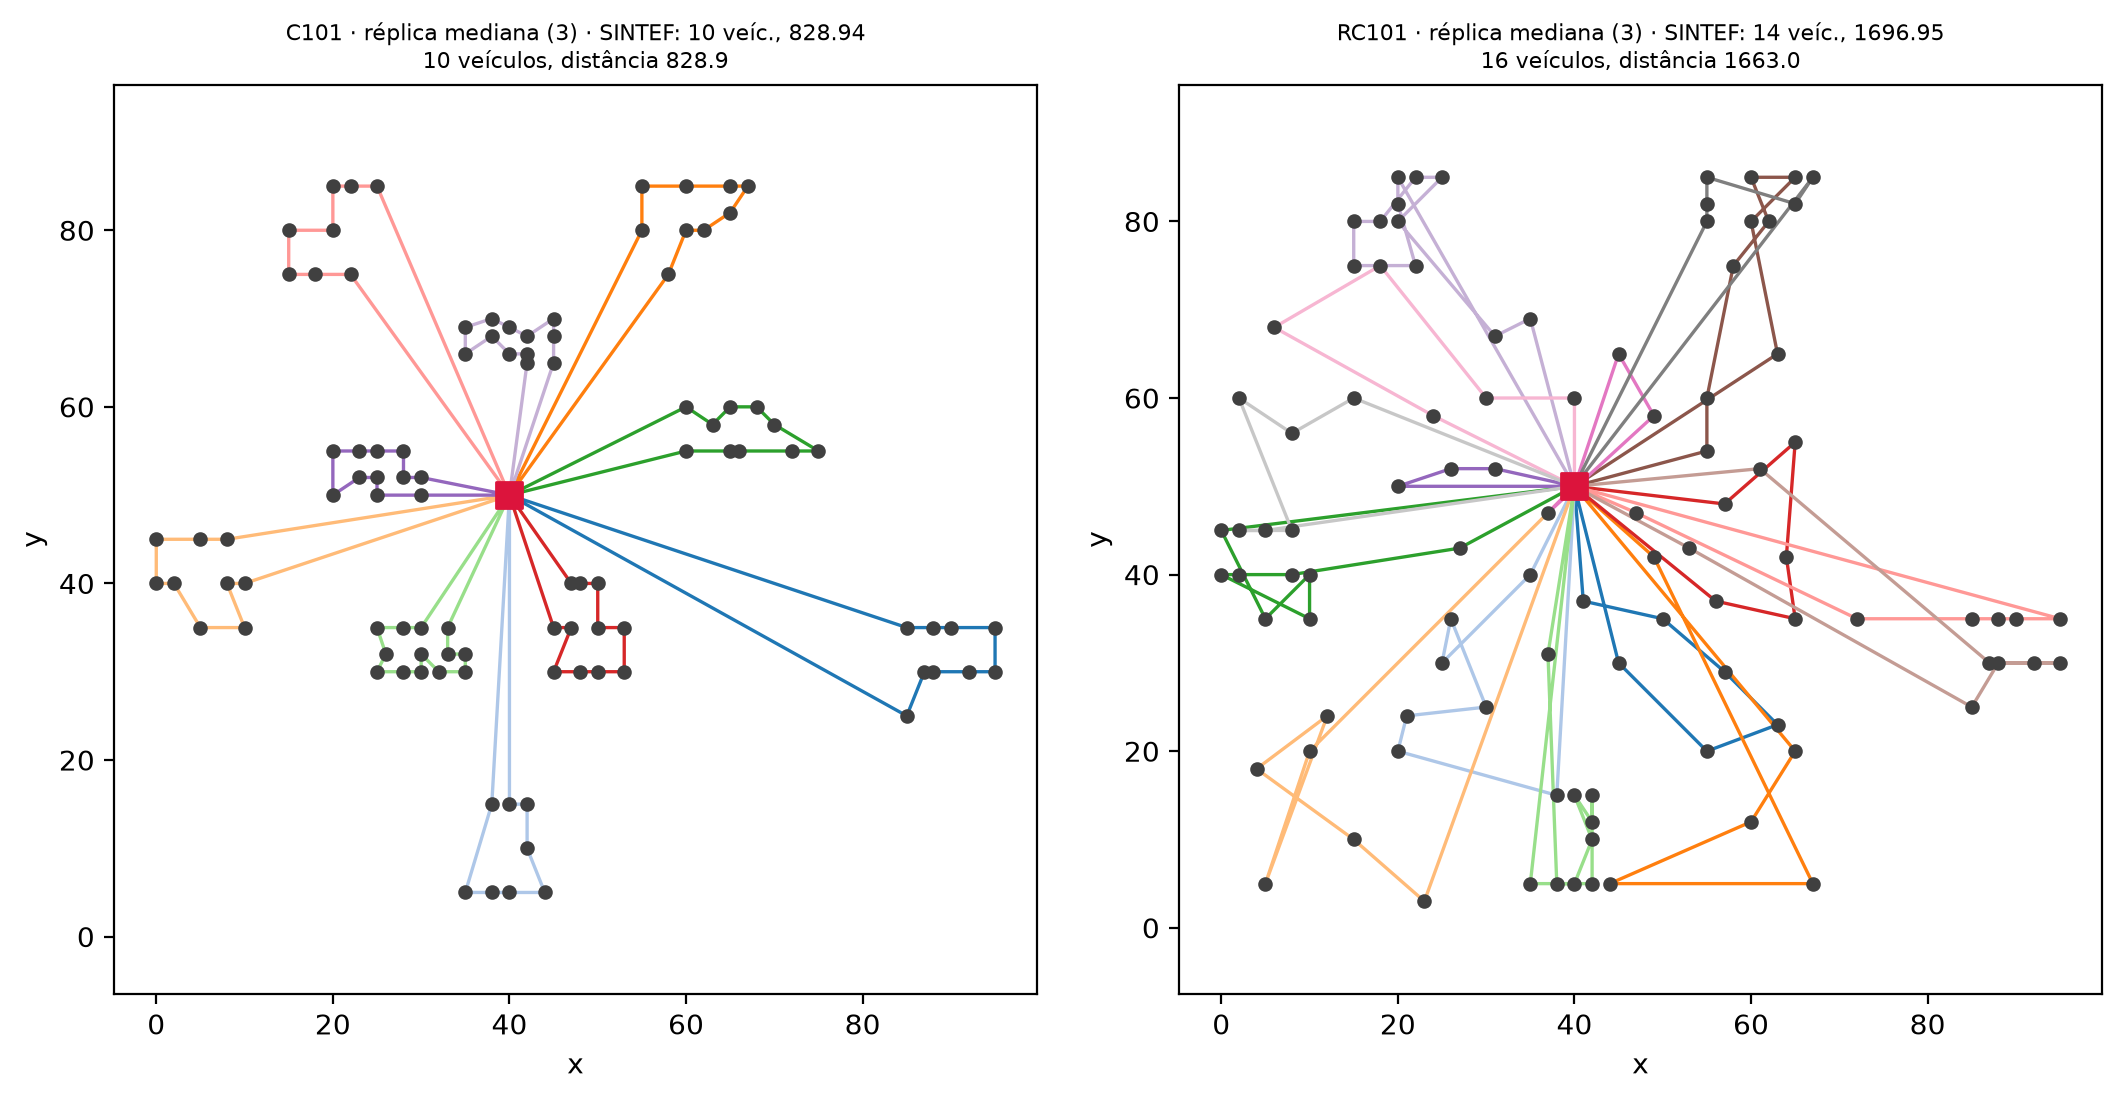

In [9]:
names = final_eval.pick_map_instances(inst)
eval_instances = results.load_eval_instances(P["sintef_zip"], split, names)

viz_results.plot_route_panels(final_eval.median_panels(names, eval_instances, rows, inst, LANG), LANG)
plt.show()

### Insight

Em C101 (réplica mediana 3), o plano emprega 10 veículos e distância 828,9, igualando a referência (10 veículos e 828,94) com rotas compactas sobre grupos vizinhos e quase sem cruzamentos. Em RC101 (réplica mediana 3), utiliza 16 veículos e distância 1663,0 contra 14 veículos e 1696,95 da referência, distância menor porém com 2 veículos extras, sem ganho lexicográfico, exibindo cruzamentos longos e pequenas rotas fragmentadas decorrentes da mistura de clientes agrupados e dispersos. Essa leitura visual qualitativa ilustra apenas dois casos selecionados por regra e não explica a causa dos dois veículos extras em RC101. Na seção 10 avaliam-se duração e espera derivadas das rotas congeladas.

## 10. Tempos das rotas congeladas

Para verificar o impacto das rotas sobre o tempo total e a parcela de espera ociosa, duração, espera e último retorno ao depósito foram recalculados após a avaliação diretamente a partir das rotas congeladas via `scripts/derive_eval_time_metrics.py`, sem acionar nenhum solver nem editar arquivos congelados (Toth & Vigo, 2014). Cada instância é representada pela réplica mediana no OR-Tools ou pela rodada única nas baselines, sob duas convenções de saída: partida simultânea no instante zero e saída ótima ajustada pela folga temporal (Savelsbergh, 1992). Como o SINTEF não publica durações, nenhuma comparação externa é feita nessa métrica; as três tabelas trazem medianas por método, perfil do OR-Tools por família e razão percentual mediana das baselines sobre o OR-Tools por instância.

,Método,Nº de instâncias,Distância (mediana),"Duração, saída às 0 (mediana)","Espera, saída às 0 (mediana)","Duração, saída ótima (mediana)","Espera, saída ótima (mediana)",Último retorno (mediana),"Espera / duração, saída às 0 (%)","Espera / duração, saída ótima (%)"
0,OR-Tools,42,979.8,2894.2,269.3,2590.8,43.1,921.4,10.3,1.6
1,Gulosa por prazo,42,2696.4,5364.6,787.0,4146.2,16.3,977.8,13.9,0.4
2,Vizinho mais próximo com janelas,42,1608.7,3608.1,382.8,3021.6,0.3,968.9,10.5,0.0


,Família,Nº de instâncias,Distância (mediana),"Duração, saída às 0 (mediana)","Espera, saída às 0 (mediana)","Duração, saída ótima (mediana)","Espera, saída ótima (mediana)",Último retorno (mediana),"Espera / duração, saída às 0 (%)","Espera / duração, saída ótima (%)"
0,C1,7,828.9,9828.9,0.0,9828.9,0.0,1234.8,0.0,0.0
1,C2,6,590.2,9626.0,36.1,9590.2,0.0,3386.9,0.4,0.0
2,R1,9,1227.7,2470.6,213.3,2300.6,54.2,228.4,9.2,2.2
3,R2,8,957.0,2526.3,545.4,2258.0,245.8,942.4,22.4,10.9
4,RC1,6,1432.5,2738.3,305.8,2496.0,41.3,237.3,11.0,1.6
5,RC2,6,1142.5,3126.9,874.5,2684.0,558.8,921.4,28.8,20.7


,Família,Método,Nº de instâncias,Distância (OR-Tools = 100%),"Duração, saída ótima (OR-Tools = 100%)"
0,Geral,Gulosa por prazo,42,258.6,144.3
1,Geral,Vizinho mais próximo com janelas,42,152.4,113.3
2,C1,Gulosa por prazo,7,261.9,115.1
3,C1,Vizinho mais próximo com janelas,7,154.9,105.0
4,C2,Gulosa por prazo,6,272.7,120.9
5,C2,Vizinho mais próximo com janelas,6,152.4,103.2
6,R1,Gulosa por prazo,9,181.4,143.7
7,R1,Vizinho mais próximo com janelas,9,133.9,115.9
8,R2,Gulosa por prazo,8,307.0,182.2
9,R2,Vizinho mais próximo com janelas,8,177.3,120.5


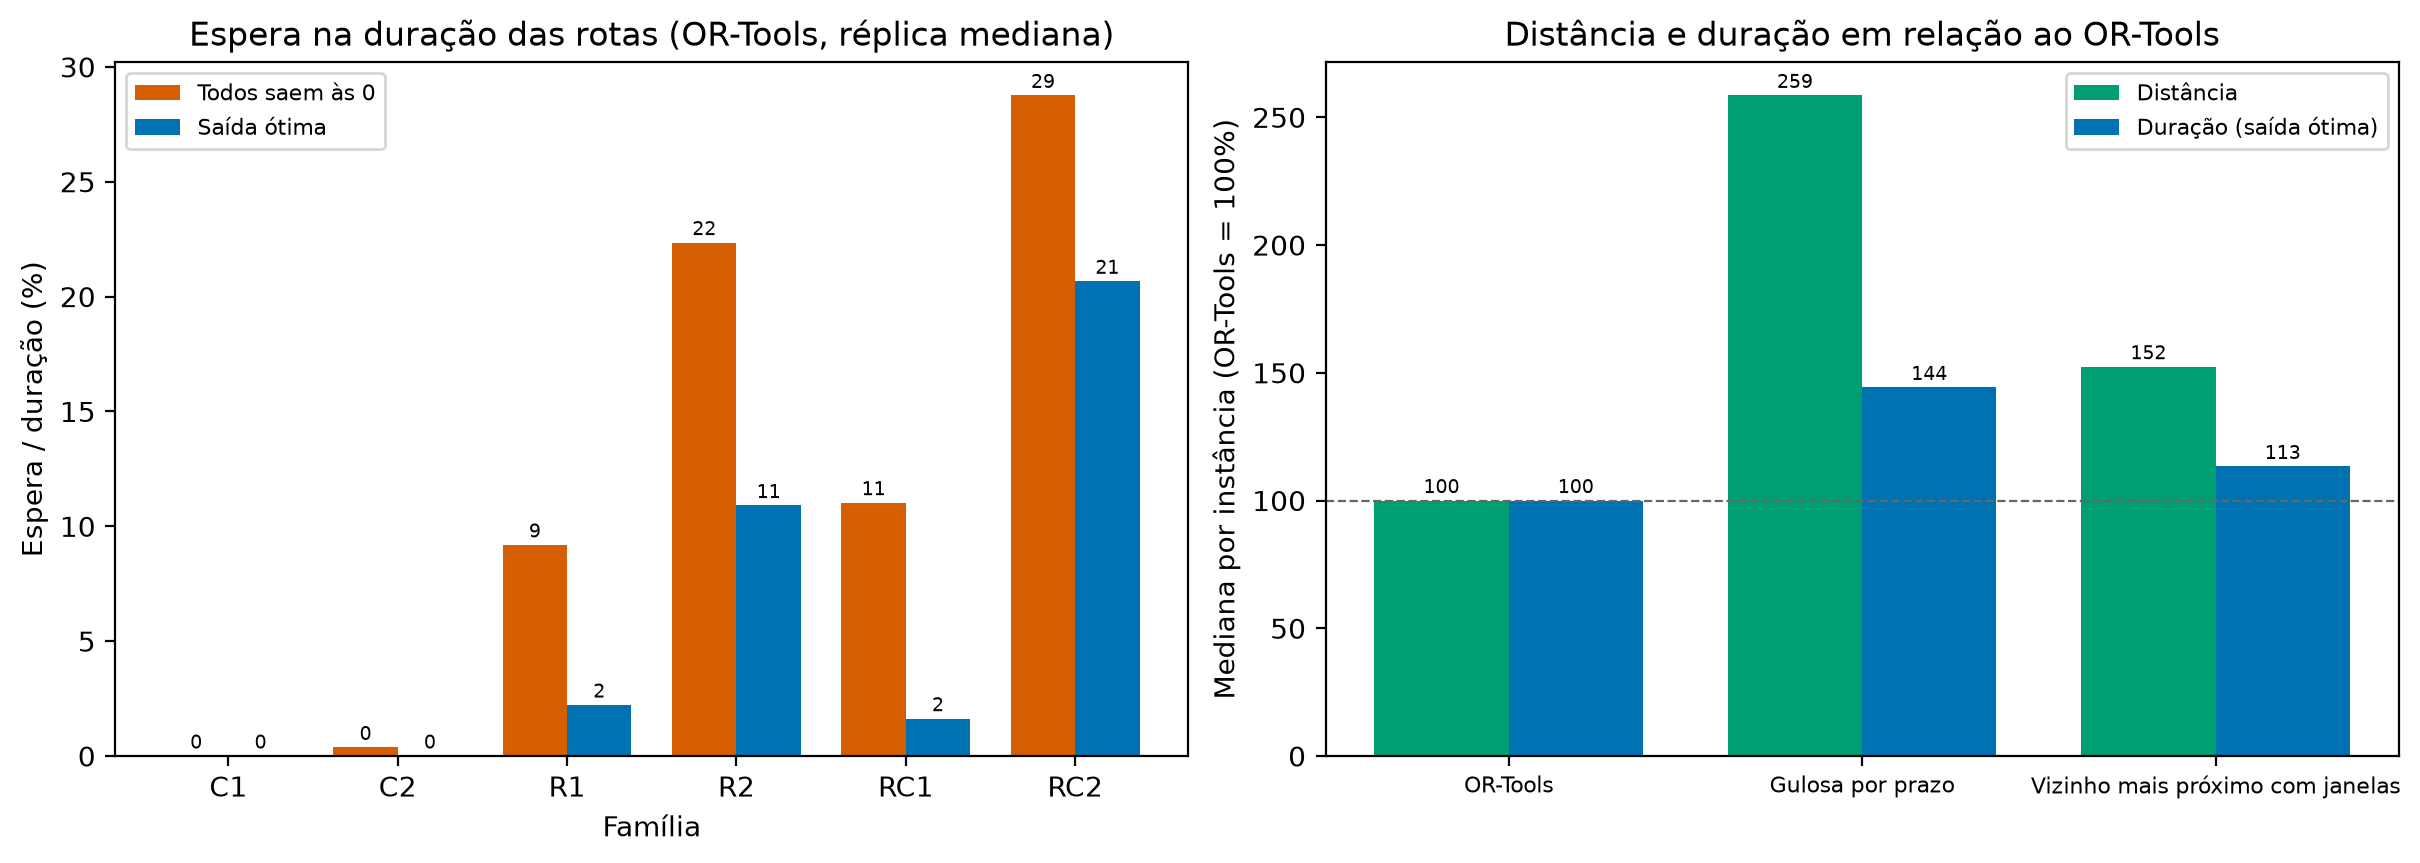

In [10]:
tm = results.load_eval_time_metrics(R["eval_time_metrics"], split)
tagg = final_eval.time_aggregate(final_eval.time_representatives(tm))

display(eda.localize_columns(final_eval.time_method_table(tagg, LANG), LANG))
display(eda.localize_columns(final_eval.time_family_table(tagg), LANG))
display(eda.localize_columns(final_eval.time_ratio_table(tagg, LANG), LANG))

viz_final.plot_time_metrics(tagg, LANG)
plt.show()

### Insight

Na réplica mediana do OR-Tools, as medianas por instância atingem 979,8 de distância, 2894,2 de duração e 269,3 de espera com partida em zero (10,3% de espera), caindo para 2590,8 de duração e 43,1 de espera sob saída ótima (1,6% de espera), com último retorno em 921,4. Com saída ótima, as baselines registram durações medianas de 4146,2 (gulosa por prazo) e 3021,6 (vizinho mais próximo), com últimos retornos em 977,8 e 968,9. Em termos pareados por instância, a gulosa tem 258,6% da distância do OR-Tools e 144,3% de sua duração, enquanto o vizinho mais próximo registra 152,4% e 113,3%.

A vantagem do OR-Tools é menor em duração do que em distância porque a duração soma tempo de serviço fixo (por exemplo, 9000 em C1 sobre distância 828,9) e porque as baselines acumulam menos espera (medianas de 16,3 e 0,3 contra 43,1). Ainda assim, o OR-Tools supera ambas as baselines em duração nas seis famílias (razões entre 103,2% e 182,2%). A espera é praticamente nula nas famílias C (0,0% e 0,4%) e expressiva nas séries 2 (22,4% em R2 e 28,8% em RC2 com saída em zero; reduzida para 10,9% e 20,7% com saída ótima, mantendo apenas a espera inevitável entre clientes). Como o solver minimiza frota e distância e as medianas misturam famílias de escalas distintas de serviço, essas métricas permanecem estritamente descritivas.

## 11. Reavaliação v2 pós-hoc

Esta seção tem caráter estritamente pós-hoc, pois as 42 instâncias de avaliação já haviam sido abertas nas análises anteriores. Após a auditoria externa e os diagnósticos da Fase B (notebook 04, seção 9), executou-se a configuração v2 sobre as mesmas 42 instâncias conforme `reports/protocolo-fase-d.md`, preservando a v1 como resultado original e principal sem substituí-la nem escolher entre versões a posteriori.

A v2 mantém os 120 s, 5 réplicas, 8 processos e baselines da v1, alterando simultaneamente a escala inteira para 10 000 (contra 100 da v1) e a regra de custo fixo relativo para k = 10 (`10 × D_ub` por veículo, correspondendo a 49,9%–66,2% dos `10^5` de custo fixo absoluto da v1 em unidades de distância). Por alterar ambos os parâmetros ao mesmo tempo, a comparação opõe duas configurações completas sem isolar o efeito puro da escala, considerando variações de distância abaixo de 0,5% sob frota igual como ruído entre execuções.

As tabelas seguintes verificam a integridade da execução v2, exibem seus resultados principais frente ao SINTEF e colocam v1 e v2 lado a lado (lendo `comparison_by_instance.csv` e recalculando o agregado compatível com `comparison_aggregate.csv`).

In [11]:
rows_v2 = results.load_evaluation(R["evaluation_v2"], split)
inst_v2 = evaluation.instance_table(rows_v2)
by_instance = results.load_evaluation_comparison(R["evaluation_v2_comparison"], split)
_, aggregate = evaluation.compare_versions(rows, rows_v2)

display(eda.localize_columns(final_eval.integrity_table(rows_v2, split, LANG), LANG))
display(eda.localize_columns(final_eval.main_table(rows_v2, LANG), LANG))
display(eda.localize_columns(final_eval.version_aggregate_table(aggregate, LANG), LANG))

,Indicador,Valor
0,Células no arquivo (total),210
1,Células do OR-Tools (instâncias × réplicas),210
2,Células das baselines,0
3,Instâncias distintas,42
4,Instâncias de avaliação no split,42
5,Instâncias de desenvolvimento nos resultados,0
6,Réplicas do OR-Tools por instância,5
7,Células factíveis no verificador,210 / 210
8,Execuções do OR-Tools com status de sucesso,210 / 210
9,Tempo médio por execução do OR-Tools (s),120.0


,Resultado,Escopo,Nº de instâncias,Δ veículos médio,Instâncias com frota igual à referência,"Gap mediano, frota igual (%)",Supera a referência
0,Réplica mediana (resultado principal),Geral,42,0.48,25,2.23,0
1,Réplica mediana (resultado principal),C1,7,0.00,7,0.0,0
2,Réplica mediana (resultado principal),C2,6,0.00,6,0.0,0
3,Réplica mediana (resultado principal),R1,9,0.89,1,0.52,0
4,Réplica mediana (resultado principal),R2,8,0.25,6,4.95,0
5,Réplica mediana (resultado principal),RC1,6,1.50,0,-,0
6,Réplica mediana (resultado principal),RC2,6,0.17,5,6.29,0


,Escopo,Nº de instâncias,Δ veículos médio (v1),Δ veículos médio (v2),Frota igual ao SINTEF (v1),Frota igual ao SINTEF (v2),"Gap mediano, frota igual (%, v1)","Gap mediano, frota igual (%, v2)","Distância dentro do ruído (< 0,5%)"
0,Geral,42,0.50,0.48,24,25,3.4,2.23,18
1,C1,7,0.00,0.00,7,7,0.0,0.0,6
2,C2,6,0.00,0.00,6,6,0.0,0.0,6
3,R1,9,0.89,0.89,1,1,0.52,0.52,3
4,R2,8,0.25,0.25,6,6,5.02,4.95,1
5,RC1,6,1.50,1.50,0,0,-,-,2
6,RC2,6,0.33,0.17,4,5,4.63,6.29,0


### Insight

A execução v2 cumpriu o protocolo da Fase D com 210 células do OR-Tools 100% factíveis e tempo exato de 120,0 s (120,00 a 120,04 s) apenas nas 42 instâncias de avaliação. Na réplica mediana, a v2 alcançou Δ médio de 0,48 (contra 0,50 da v1), igualando a frota SINTEF em 25 instâncias (contra 24) com gap mediano de 2,23% (contra 3,40%). Nada se alterou em C1, C2, R1 e RC1; R2 manteve Δ 0,25 e 6 igualdades (gap mediano de 5,02% para 4,95%), enquanto RC2 mudou de Δ 0,33 para 0,17 e de 4 para 5 igualdades (alterando a mediana do gap de 4,63% para 6,29% pela inclusão de mais uma instância). Ao todo, 18 de 42 instâncias permaneceram dentro da faixa de ruído de 0,5%. Trata-se de comparação pós-hoc descritiva sobre conjuntos distintos de igualdade de frota, sem isolamento entre escala e magnitude de custo fixo (comparados na próxima tabela).

A tabela abaixo compara o custo fixo por veículo entre v1 (valor constante de `10^5` unidades de distância) e v2 (`10 × D_ub`, soma das viagens de ida e volta depósito-cliente-depósito) nas 42 instâncias de avaliação, geral e por família.

In [12]:
fixed_cost = final_eval.evaluation_fixed_cost_table(
    P["sintef_zip"], split, rows_v2["instance"].unique(), max(cfg.v2.scales), cfg.v2.k_default
)
display(eda.localize_columns(final_eval.fixed_cost_ratio_summary(fixed_cost, LANG), LANG))


,Escopo,Nº de instâncias,Custo fixo v1 (unid. de distância),"Custo fixo v2 / v1, mínimo (%)","Custo fixo v2 / v1, mediana (%)","Custo fixo v2 / v1, máximo (%)",Instância do mínimo,Instância do máximo
0,Geral,42,100000.0,49.9,57.7,66.2,R101,RC101
1,C1,7,100000.0,57.7,57.7,57.7,C101,C101
2,C2,6,100000.0,59.4,59.4,59.4,C201,C201
3,R1,9,100000.0,49.9,49.9,49.9,R101,R101
4,R2,8,100000.0,49.9,49.9,49.9,R203,R203
5,RC1,6,100000.0,66.2,66.2,66.2,RC101,RC101
6,RC2,6,100000.0,66.2,66.2,66.2,RC201,RC201


### Insight

Enquanto o custo fixo da v1 permanece constante em 100 000 unidades de distância (cerca de 15 a 20 vezes `D_ub`), o valor relativo `10 × D_ub` da v2 varia por instância e corresponde a 49,9% do da v1 no mínimo (R1 e R2, como R101), 57,7% na mediana geral (57,7% em C1, 59,4% em C2) e 66,2% no máximo (RC1 e RC2, como RC101). Desse modo, a descrição inicial de que k = 10 teria magnitude equivalente à da v1 mostrou-se incorreta: v2 difere de v1 simultaneamente na escala e no custo fixo, fazendo com que o ganho observado em RC207 seja atribuível à configuração v2 como um todo. Os experimentos controlados anteriores na partição de desenvolvimento isolaram a escala em B1 e mantiveram frota inalterada sob variações de k em B2, mas nenhum experimento separou os dois fatores nas instâncias de avaliação. Em seguida, compara-se instância por instância.

Os quadros e o gráfico confrontam as versões v2 e v1 instância por instância, listando as mudanças de frota e variações de distância iguais ou superiores a 0,5% sob frota comum, junto à banda de ruído destacada na figura.

,Item,Quantidade,Detalhe
0,Instâncias comparadas,42,
1,Frota menor na v2,1,RC207
2,Frota maior na v2,0,
3,Frota igual nas duas versões,41,
4,Distância dentro do ruído (frota igual),18,|Δ| < 0.5%
5,"Distância menor na v2, além do ruído",11,Δ ≤ −0.5%
6,"Distância maior na v2, além do ruído",12,Δ ≥ +0.5%
7,Menor diferença de distância,-,-4.3%
8,Maior diferença de distância,-,+2.1%


,Instância,Família,Veículos SINTEF,Veículos (v1),Veículos (v2),Distância (v1),Distância (v2),Distância v2 contra v1 (%),"Gap da v2 ao SINTEF (%, frota igual)"
0,RC207,RC2,3,4,3,1039.1,1178.6,-,11.07
1,RC204,RC2,3,3,3,843.7,807.6,-4.28,1.14
2,R109,R1,11,12,12,1227.7,1179.3,-3.95,-
3,RC202,RC2,3,4,4,1245.8,1198.7,-3.79,-
4,C104,C1,10,10,10,888.3,860.7,-3.1,4.36
5,R205,R2,3,3,3,1072.3,1042.8,-2.74,4.87
6,R107,R1,10,11,11,1107.3,1092.8,-1.32,-
7,RC107,RC1,11,12,12,1279.3,1264.4,-1.16,-
8,R209,R2,3,3,3,961.9,950.8,-1.15,4.58
9,RC205,RC2,4,4,4,1341.3,1326.6,-1.1,2.23


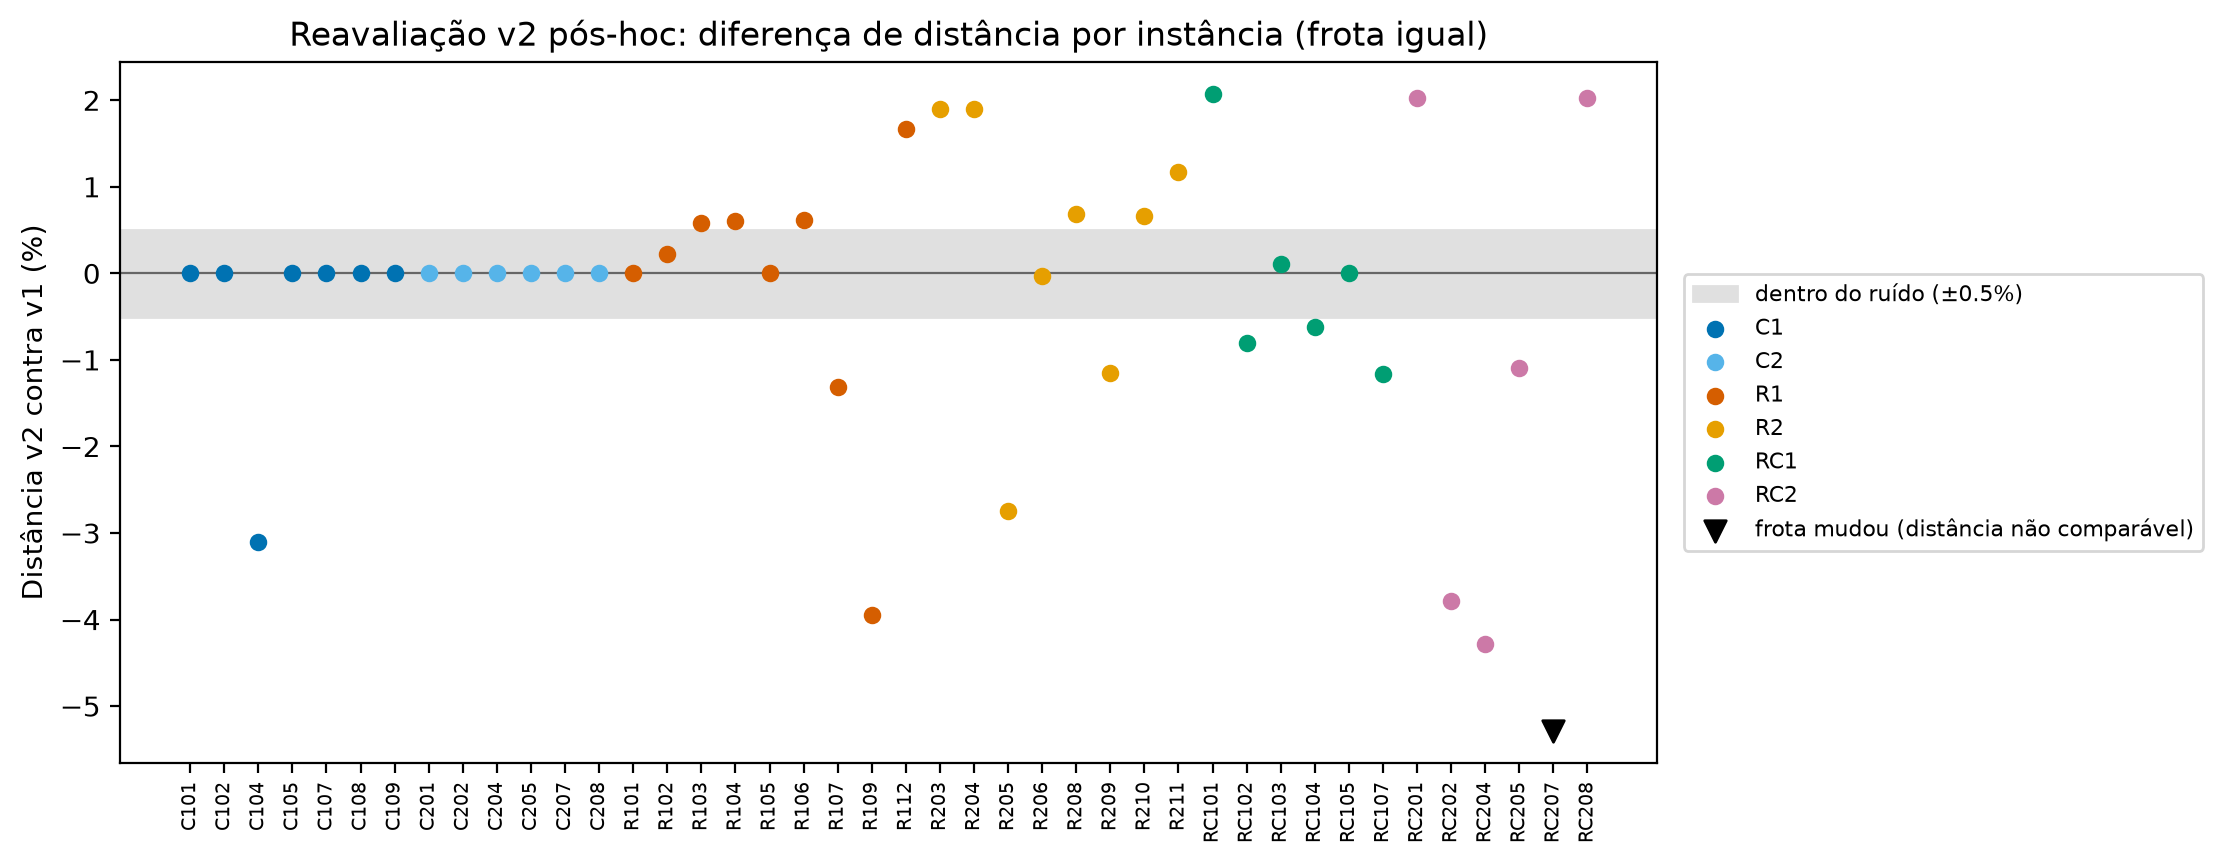

In [13]:
display(eda.localize_columns(final_eval.version_distance_summary(by_instance, LANG), LANG))
display(eda.localize_columns(final_eval.version_changes(by_instance, LANG), LANG))

viz_final.plot_version_comparison(by_instance, LANG)
plt.show()

### Insight

A frota mudou em apenas uma das 42 instâncias: RC207 caiu de 4 para 3 veículos na v2, igualando o SINTEF com distância de 1039,1 para 1178,6 (gap de 11,07% sobre a referência). A expectativa registrada previamente de ganho concentrado em instâncias de janelas apertadas como R106 não se confirmou, mantendo R106 em 13 veículos nas duas versões (+0,61% de distância). Entre as 41 instâncias de frota idêntica, 18 variaram abaixo de 0,5%, 11 encurtaram além do ruído (até −4,28% em RC204) e 12 alongaram (até +2,07% em RC101), indicando oscilação nos dois sentidos (−4,3% a +2,1%) sem tendência sistemática. Logo, a redução da mediana geral de gap de 3,40% para 2,23% decorre dessas flutuações bilaterais e da entrada de RC207, não de ganho uniforme de distância. A estabilidade das 5 réplicas na v2 é verificada a seguir.

A tabela aplica a mesma verificação de variabilidade da seção 6 às 5 réplicas da v2, listando instâncias com oscilação de distância.

In [14]:
display(eda.localize_columns(final_eval.variability_table(inst_v2, LANG), LANG))
display(eda.localize_columns(final_eval.varying_instances(inst_v2), LANG))

,Escopo,Nº de instâncias,Instâncias com frota variável,Maior amplitude de frota,Instâncias com distância variável,Amplitude mediana da distância (%),Amplitude máxima da distância (%)
0,Geral,42,0,0,4,0.0,3.02
1,C1,7,0,0,0,0.0,0.00
2,C2,6,0,0,0,0.0,0.00
3,R1,9,0,0,3,0.0,0.74
4,R2,8,0,0,0,0.0,0.00
5,RC1,6,0,0,0,0.0,0.00
6,RC2,6,0,0,1,0.0,3.02


,Instância,Família,Veículos,Distância mínima,Distância,Distância máxima,Amplitude (%)
0,RC208,RC2,3,861.82,887.87,887.87,3.02
1,R112,R1,10,992.86,1000.22,1000.22,0.74
2,R106,R1,13,1269.41,1269.41,1271.23,0.14
3,R107,R1,11,1091.67,1092.76,1092.76,0.10


### Insight

Tal como na v1, a frota da v2 manteve-se invariante entre as 5 réplicas em todas as 42 instâncias. A distância oscilou em apenas 4 casos (RC208 em 3,02%, R112 em 0,74%, R106 em 0,14% e R107 em 0,10%), contra 6 na v1, com mediana geral de 0,00% e variabilidade zero nas famílias C, R2 e RC1. Assim, divergências pontuais como os −3,1% em C104 entre v1 e v2 excedem o ruído interno de réplicas, embora a causa específica permaneça não isolada. Em suma, a escala 10 000 corrige o defeito de truncamento visto em R106 e R110 e a v2 iguala a frota em RC207, mas o efeito agregado é marginal e preserva a conclusão original da v1.

## 12. Síntese e limitações

Nas 42 instâncias de avaliação inéditas, a configuração congelada sob o protocolo pré-registrado alcançou 100% de factibilidade nas 294 células, com Δ médio de 0,50 veículo frente ao SINTEF, igualdade de frota em 24 casos e teto máximo de +2 veículos. O desempenho aproximou-se da referência nas famílias C (frota igual em todas as 13 instâncias, com 10 reproduzindo a distância ao centésimo) e nas séries 2 (10 igualdades em 14 casos, com gaps de 3,4% a 7,8%), encontrando seu limite nas séries 1 de janelas apertadas (R1 e RC1), onde apenas 1 de 15 instâncias empatou em frota e ocorreram os 3 casos de +2 veículos. A frota mostrou-se estável entre réplicas em 100% dos casos e o solver superou amplamente as duas baselines (Δ médio 0,50 contra 1,36 e 3,98), mantendo coerência com o comportamento medido no desenvolvimento.

Na análise derivada de duração (seção 10), a mediana com saída ótima foi de 2590,8 no OR-Tools contra 3021,6 do vizinho mais próximo e 4146,2 da gulosa por prazo, com espera atingindo 22,4% em R2 e 28,8% em RC2 na saída em zero, lembrando que duração e espera não integram o objetivo do solver. Na reavaliação v2 pós-hoc (seção 11), a combinação de escala 10 000 e custo fixo relativo reduziu RC207 de 4 para 3 veículos, movendo o Δ médio de 0,50 para 0,48 (24 para 25 igualdades) com oscilações bidirecionais de distância (−4,3% a +2,1%), efeito agregado marginal que mantém a v1 como resultado principal.

Esses achados permanecem estritamente descritivos e não sustentam alegações de otimalidade (pois o SINTEF publica heurísticas e o solver opera sob limite de tempo), atribuição causal para veículos extras em R1 e RC1, generalização direta para operação logística real (visto tratar-se de benchmark sintético) ou superioridade irrestrita sobre outras arquiteturas não avaliadas. A v2 tampouco substitui a v1 nem isola o efeito puro da escala em RC207. Como registro protocolar, durante a execução desta avaliação um agente editou o notebook 04 sob regra de não executar código, gerando carga residual de CPU que não alterou a estabilidade absoluta de frota nas 5 réplicas, ainda que não exclua pequenas variações de distância nas 6 instâncias com dispersão.

Na sequência, o notebook 06 explora cenários de negócio com flexibilização de janelas nas instâncias de desenvolvimento (sem comparação com o SINTEF), enquanto o notebook 07 analisa a robustez dos planos fixos sob atrasos e restrições operacionais.

## Referências

- Barr, R. S., Golden, B. L., Kelly, J. P., Resende, M. G. C., & Stewart, W. R. (1995). Designing and reporting on computational experiments with heuristic methods. *Journal of Heuristics, 1*(1), 9–32.
- Bräysy, O., & Gendreau, M. (2005a). Vehicle routing problem with time windows, Part I: Route construction and local search algorithms. *Transportation Science, 39*(1), 104–118.
- Clarke, G., & Wright, J. W. (1964). Scheduling of vehicles from a central depot to a number of delivery points. *Operations Research, 12*(4), 568–581.
- Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data, 6*(4), Article 15.
- Nosek, B. A., Ebersole, C. R., DeHaven, A. C., & Mellor, D. T. (2018). The preregistration revolution. *Proceedings of the National Academy of Sciences, 115*(11), 2600–2606.
- Perron, L., & Furnon, V. (2026). *OR-Tools* (Version 9.15) [Computer software]. Google. https://developers.google.com/optimization/
- Savelsbergh, M. W. P. (1992). The vehicle routing problem with time windows: Minimizing route duration. *ORSA Journal on Computing, 4*(2), 146–154.
- SINTEF. (2008). *VRPTW — 100 customers: Solomon benchmark, best known solutions*. SINTEF TOP. https://www.sintef.no/projectweb/top/vrptw/100-customers/
- Toth, P., & Vigo, D. (Eds.). (2014). *Vehicle routing: Problems, methods, and applications* (2nd ed.). SIAM.
- Voudouris, C., & Tsang, E. (1999). Guided local search and its application to the traveling salesman problem. *European Journal of Operational Research, 113*(2), 469–499.